# Learning not to mix tasks: 2-task multi-MNIST

The experiment of `../04_fully_connected.ipynb`, moved from multi-GEOFF to multi-MNIST. In a fully connected network
there are no distractors to remove; the question is whether our method from `../01_distractors.ipynb` learns to keep the
tasks' information apart, and so does as well as with the ideal connectivity, which builds the problem's structure in.

**Problem.** 2-task multi-MNIST, as in the connectivity paper: each sample concatenates 2 independently drawn MNIST
training images, and each task's target is its own image's label. The images are downsampled to 14×14 by averaging
2×2 blocks, which keeps each run to a few minutes. Each pixel is centered on its mean over the training set, and all
pixels are scaled by one standard deviation over every pixel (scaling each pixel by its own would blow rarely-lit
pixels up to values near 250, which would collapse Autostep's step-sizes through its per-row normalization). It is
non-stationary: every 1000 steps, one task (chosen at random) gets a new random mapping from digits to labels, so each
task changes about every 2000 steps. The loss is the sum of each task's softmax cross-entropy.

**Networks.** 392 inputs → 20 LTU hidden units → 20 linear outputs (2 groups of 10 logits), each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's image and feeding only its own task's
  logits.

**Learners.** As in `../04_fully_connected.ipynb`, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$:
- *ours*: centered hidden units with a matching centered backward pass, and input weights starting at
  $U(-\alpha_0, \alpha_0)$;
- *standard Autostep*: raw hidden units, and input weights starting LeCun uniform.

Each learner trains both networks. 1M steps and 30 seeds; seed $s$ gives every run the same initial-weight draw, images
and label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, pooled over seeds:
- **H1**, ours learns not to mix: fully connected, ours is at most 1 percentage point below ours with ideal
  connectivity.
- **H2**, mixing is a real cost: fully connected, standard Autostep is more than 1 percentage point below standard
  Autostep with ideal connectivity.

Question 2, after the results, shows a simple generate and test as the next step for the fully connected
network's shortfall. (Shadow weights, which fix it by building in the right split, are in
`shadow_weights.ipynb`.)

**Diagnostics**, fixed in advance, for the fully connected runs:
1. *Path purity*: the share of all input → hidden → output path weight (the product of $|w|$ along the path) that
   starts and ends in the same task. 1 means no path crosses tasks; 1/2 that the units mix the tasks evenly. Pooling
   over all paths means a task with almost no paths barely counts.
2. *Allocation*: how evenly the hidden units are split between the tasks, counting each unit for the task whose outputs
   it feeds most. 1 means 10 units each; 0 means all 20 feed one task. An uneven split costs capacity even without
   mixing. At step 1 most units' output weights still favour neither task, and a tie counts for the first task, so
   allocation starts low.

Everything is recorded at step 1, then averaged over each window of 4000 steps. The plots show the mean over seeds,
with $\pm 2$ standard errors shaded.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10               # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records the mean loss, accuracy, path purity and allocation

# --- Generate and test (Question 2) ---
REINIT_PERIODS = (10_000, 50_000, 100_000)       # steps between resets of the unit with the smallest output weights

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 3,920 weights, w2 200 weights
fully connected: w1 7,840 weights, w2 400 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden = masks['w1'].shape[0]
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, labels, masks, ours):
    # One online Autostep update on the summed softmax cross-entropy of every task. Returns the new learner, the loss
    # and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [6]:
WINDOW = NUM_STEPS // N_WINDOWS


def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    n_hidden = w['w1'].shape[0]
    reads = jnp.abs(w['w1'][:, :-1]).reshape(n_hidden, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    n_hidden = w['w1'].shape[0]
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / n_hidden
    return (1 - largest) / (1 - 1 / N_TASKS)


def generate_and_test(learner, key, step, period, masks):
    # Every `period` steps, the hidden unit with the smallest mean |output weight| starts over as a new unit: its
    # weights, step-sizes, Autostep traces and running means are set to those of a freshly initialized network (output
    # weights 0, input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    n_hidden = learner.hidden_mean.shape[0]
    unit = jnp.argmin(jnp.abs(learner.w['w2'][:, :-1]).mean(0))
    fresh = init_learner(jax.random.fold_in(key, step), masks, ours=True)
    is_unit = jnp.arange(n_hidden) == unit
    parts = {'w1': is_unit[:, None], 'w2': jnp.append(is_unit, False)[None, :]}     # the unit's row of w1, column of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    reset = learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(is_unit, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(is_unit[:, None], fresh.hidden_slope, learner.hidden_slope))
    return jax.tree.map(lambda new, old: jnp.where(step % period == 0, new, old), reset, learner)


def recorded_values(learner, loss, accuracy):
    # What each step records: the loss and accuracy on its sample (before learning from it), and the path purity and
    # allocation after its update.
    return {'loss': loss, 'accuracy': accuracy, 'purity': path_purity(learner.w), 'allocation': allocation(learner.w)}


def train(key, stream, masks, ours, reinit_period=None):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with generate and test every `reinit_period` steps (if
    # given). Returns the loss, accuracy, path purity and allocation: at step 1, then averaged over every window.
    def one_step(carry, _):
        learner, stream, total = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours)
        if reinit_period is not None:
            learner = generate_and_test(learner, key, stream.step, reinit_period, masks)
        total = jax.tree.map(jnp.add, total, recorded_values(learner, loss, accuracy))
        return (learner, stream, total), None

    def window(carry, _):
        zeros = jax.tree.map(jnp.zeros_like, first)
        (learner, stream, total), _ = jax.lax.scan(one_step, (*carry, zeros), length=WINDOW)
        return (learner, stream), jax.tree.map(lambda t: t / WINDOW, total)

    stream, (x, labels) = next_sample(stream)
    learner, loss, accuracy = learner_step(init_learner(key, masks, ours), x, labels, masks, ours)
    first = recorded_values(learner, loss, accuracy)
    values = jax.lax.scan(window, (learner, stream), length=N_WINDOWS)[1]
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, values)


def run(network, ours, reinit_period=None):
    # Trains one learner (ours, or standard Autostep) on `network` (a key of MASKS) on every seed, vmapped into one
    # scan, with generate and test every `reinit_period` steps (if given). Seed s uses init key s and stream s for every
    # run, so runs are paired. Returns per-seed records: loss, accuracy, purity and allocation (seed, step 1 + window).
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS))
    masks = MASKS[network]
    train_seeds = jax.vmap(lambda key, stream: train(key, stream, masks, ours, reinit_period))
    records = jax.jit(train_seeds)(keys, streams)
    return jax.tree.map(np.asarray, records)

## Results

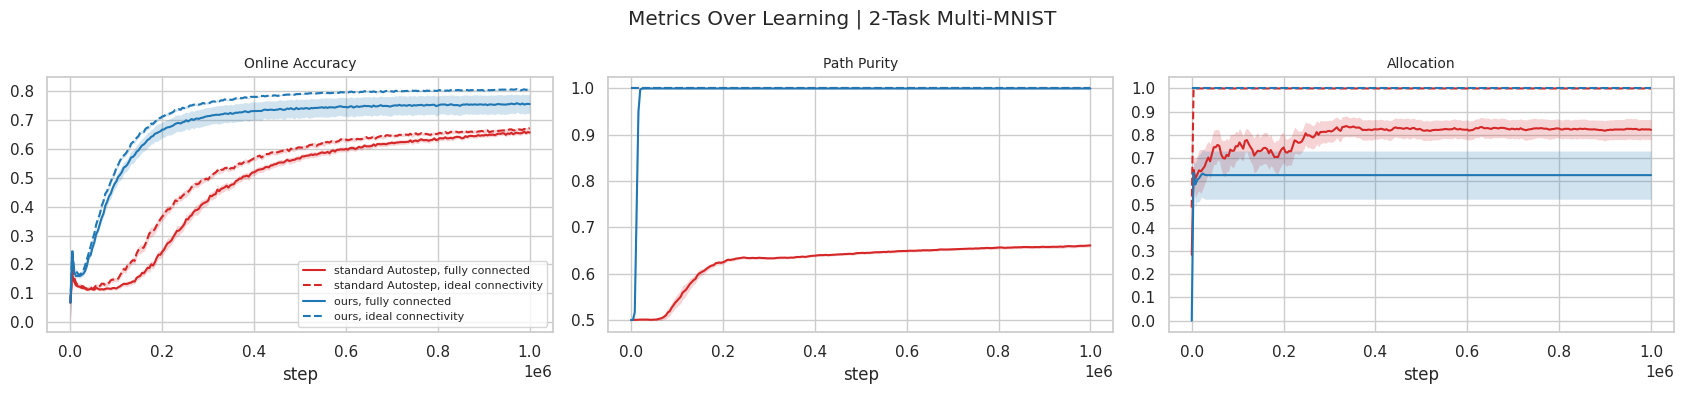

standard Autostep, fully connected      online accuracy 65.34%
standard Autostep, ideal connectivity   online accuracy 66.56%
ours, fully connected                   online accuracy 75.56%
ours, ideal connectivity                online accuracy 80.59%
H1, ours, fully connected vs ours, ideal connectivity: -5.0 points (± 3.3): failed
H2, standard Autostep, fully connected vs standard Autostep, ideal connectivity: -1.2 points (± 0.6): held


In [7]:
STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def plot_runs(runs, colors, title, dashed=()):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds), drawn in
    # `colors[label]`, and dashed for the labels in `dashed`.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, panel) in zip(axes, [('accuracy', 'Online Accuracy'), ('purity', 'Path Purity'),
                                       ('allocation', 'Allocation')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(STEPS, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5, label=label)
            ax.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(panel, fontsize=10)
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{title} | 2-Task Multi-MNIST')
    fig.tight_layout()
    plt.show()


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def report(runs, tests):
    # Prints every run's accuracy, then for each test (name, label, reference, claim) the per-seed gap of `label` to
    # `reference` (mean and 2 SE over paired seeds), and whether the claim held: 'within' ACCURACY_TOLERANCE of it, or
    # more than that 'below' it (no claim: None).
    width = max(map(len, runs))
    for label, res in runs.items():
        print(f'{label:<{width}}   online accuracy {final_accuracy(res).mean():.2%}')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        ok = g.mean() >= -ACCURACY_TOLERANCE if claim == 'within' else g.mean() < -ACCURACY_TOLERANCE
        verdict = '' if claim is None else f': {"held" if ok else "failed"}'
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}){verdict}')


runs = {'standard Autostep, fully connected': run('fully connected', ours=False),
        'standard Autostep, ideal connectivity': run('ideal connectivity', ours=False),
        'ours, fully connected': run('fully connected', ours=True),
        'ours, ideal connectivity': run('ideal connectivity', ours=True)}
# Color by learner; dashed for the ideal connectivity.
plot_runs(runs, {label: 'tab:blue' if label.startswith('ours') else 'tab:red' for label in runs},
          'Metrics Over Learning', dashed=[label for label in runs if label.endswith('ideal connectivity')])
report(runs, [('H1', 'ours, fully connected', 'ours, ideal connectivity', 'within'),
              ('H2', 'standard Autostep, fully connected', 'standard Autostep, ideal connectivity', 'below')])

## Results

- **H1 failed.** Fully connected, ours reaches 75.6% online accuracy against 80.6% with ideal connectivity: −5.0
  points (± 3.3, 2 SE over paired seeds).
- **H2 held.** Fully connected, standard Autostep is −1.2 points (± 0.6): 65.3% against 66.6%.
- Ours beats standard Autostep on both networks, by 10.2 points fully connected and by 14.0 with ideal connectivity.
- **Diagnostics.** Ours never mixes the tasks: its path purity reaches 1 within about 20k steps, against about 0.66
  for standard Autostep. But it splits its hidden units unevenly, and early: its allocation settles at about 0.63
  within about 20k steps and never changes, while standard Autostep's reaches about 0.82. So ours' gap to the ideal
  network comes from allocation: in a debugging run with 5 units per task, fixing the split at 5/5 closed the gap.

## Question 2: how does generate and test approach the ideal connectivity?

Fully connected, our method falls short of the ideal connectivity only because it splits the hidden units unevenly
between the tasks early on and never revises the split. Feature search is the natural next step: let the network
replace units, so that a task with too few can gain more. This is a simple version, not a tuned algorithm. Every reset
period, the hidden unit with the smallest mean $|$output weight$|$ starts over as a new unit: output weights 0, input
weights $U(-\alpha_0, \alpha_0)$, step-sizes $\alpha_0$, zero Autostep traces, and its running means at their initial
values. Our learner, fully connected, with reset periods of 10k, 50k and 100k steps, against the same network without
generate and test and with the ideal connectivity (the runs at the top). The gaps printed below are to the ideal
connectivity, on paired seeds.

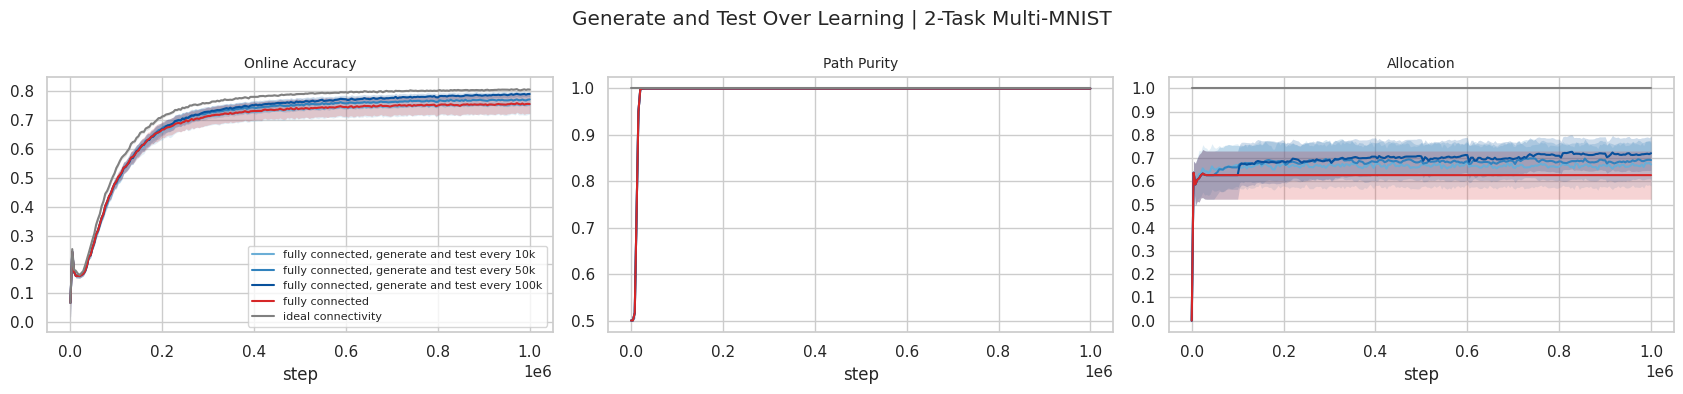

fully connected, generate and test every 10k    online accuracy 75.33%
fully connected, generate and test every 50k    online accuracy 77.00%
fully connected, generate and test every 100k   online accuracy 78.88%
fully connected                                 online accuracy 75.56%
ideal connectivity                              online accuracy 80.59%
gap, fully connected, generate and test every 10k vs ideal connectivity: -5.3 points (± 3.4)
gap, fully connected, generate and test every 50k vs ideal connectivity: -3.6 points (± 2.0)
gap, fully connected, generate and test every 100k vs ideal connectivity: -1.7 points (± 0.9)


In [8]:
labels = [f'fully connected, generate and test every {p // 1000}k' for p in REINIT_PERIODS]
gnt_runs = {**{label: run('fully connected', True, reinit_period=p) for label, p in zip(labels, REINIT_PERIODS)},
            'fully connected': runs['ours, fully connected'],
            'ideal connectivity': runs['ours, ideal connectivity']}
plot_runs(gnt_runs, {**dict(zip(labels, ('#6baed6', '#3182bd', '#08519c'))), 'fully connected': 'tab:red',
                     'ideal connectivity': 'gray'}, 'Generate and Test Over Learning')
report(gnt_runs, [('gap', label, 'ideal connectivity', None) for label in labels])

**Result.** Generate and test moves the fully connected network toward the ideal connectivity, more so the longer
the reset period: 75.3%, 77.0% and 78.9% online accuracy with resets every 10k, 50k and 100k steps, against 75.6%
without it and 80.6% with the ideal connectivity (gaps to ideal −5.3 ± 3.4, −3.6 ± 2.0 and −1.7 ± 0.9 points).
Allocation rises from 0.63 to about 0.7, and path purity stays at 1.

This simple version is limited: a new unit starts with every step-size at $\alpha_0$ and output weights at 0, and in a
separate diagnostic run (resets every 100k steps) it got going only in the seeds where one task had 3 or fewer units,
always joining that task (gains of 6.5 to 27 points there, about none elsewhere). Elsewhere it stays inert, so the next
reset picks it again. Closing the rest of the gap needs a better search, which has to trade searching for better
features against keeping the solution it has; that is beyond this notebook. (Allocation counts an inert new unit for
whichever task its near-zero output weights favour, so the generate-and-test curves are noisy by about one unit.)